# Assignment 4 — A Multi-Agent Help Desk

Authored by Dr. Tiziana Ligorio for AI Agents - CSCI 395.32, Hunter College, CUNY.

> **Run this notebook locally.** Follow `SETUP.md` first; it takes about 15 minutes.

**Work in pairs. Submit one notebook and one results file per pair.**

**What you are building:** the **Riverview College help desk**, a multi-agent system built with LangGraph. A student sends one message that can ask for several things at once, for example:

> *"I'm S104. What do I still need for my CS major? And can you find me spring sections of CSCI 310 and ENG 101 that don't conflict?"*

The system splits the message into parts and sends each part to a **specialist agent**. The specialists work **in parallel**, each in its own context:

* the **degree-progress specialist** works out which required courses the student still needs;
* a **section finder**, one per course, picks a Spring 2027 section the student can take.

Then plain code **checks** the picks (are they real open sections? do two picks conflict with each other?), sends a section finder back once if needed, and **combines** everything into one answer.

```
START → plan → [degree_progress ∥ find_section ∥ find_section …] → check → combine → END
                                       ↑                              │
                                       └──── retry once ──────────────┘
```

You use the Riverview data from Assignment 3, and all five tools are provided. This assignment is about the multi-agent system: how the work is split, what each agent is told, how the results are checked, and how the graph is wired. It follows the LangGraph multi-agent tutorial closely.

## Learning goals

By the end of the assignment, you should be able to:

- split a request into independent parts and route each part to the right specialist with `Send`;
- give each specialist a small, coherent set of tools and a clear brief, so it can work in an isolated context;
- check the specialists' combined work in plain code, and send work back when it fails; and
- build and run a LangGraph graph with shared state, a reducer, conditional edges, and parallel branches.

## What you will do

1. Run the setup check and read the data, the tools, and the answer formats (§1–4).
2. Write the plan prompt (§5, YOUR WORK 1).
3. Write `route`, and pass its public tests (§6, YOUR WORK 2).
4. Write the two specialists: their prompts, their tools, and the nodes that brief them (§7, YOUR WORK 3).
5. Write `check` and `after_check`, and pass their public tests (§8, YOUR WORK 4).
6. Write `build_graph` (§9, YOUR WORK 5).
7. Run the system on the public questions. When a question fails, read what went wrong, change one thing, and rerun, until every public question passes (§10).
8. Save your results and disclose any AI assistance (§11–12).

The public tests and questions are a sample. Your system should work for any student, course, or question of the same kinds, so write general rules, not one per question.

Cells marked `# DO NOT MODIFY` are provided; do not change them. Write only in the cells marked `# YOUR WORK n`, and do not change their first line. Read every provided cell about the agents: the tools, the formats, the state, and the nodes are part of what you are expected to understand. Cells that only test or save your work say **"You don't need to read this code."**

Each partner has an individual Understanding Check: be ready to explain any cell of your submission, and any provided cell about the agents.

## Deliverables

- This notebook, with its **saved outputs**.
- `results.json`, which §11 writes.

Do not submit your `.env` file or your API key.

## Using AI assistants in this assignment

You may use an AI assistant as a learning partner, for example to explain a LangGraph error or to discuss why a prompt rule did not take effect. You remain responsible for understanding and testing every cell you submit. Do not give an assistant this notebook and ask it to write your prompts or functions. At the end, disclose what assistance you used and what you checked yourself.

## 1. Setup

Run the setup check first. It confirms that the notebook is using the project's Python, that the packages are installed, that the `data/` folder is next to the notebook, and that your OpenRouter key is in `.env`. If a check fails, its message names the `SETUP.md` step that fixes it.

Every agent in this course uses the same model, `openai/gpt-4.1-mini` at temperature 0 through OpenRouter, so results are comparable across teams.

In [1]:
# Setup check: run this cell first. If anything fails, follow SETUP.md.
import sys
from pathlib import Path

print("Python", sys.version.split()[0])
assert sys.version_info >= (3, 11), "This is not the project's Python. See SETUP.md, step 6 (select the .venv kernel)."
try:
    import dotenv, langchain, langchain_openai, langgraph, pydantic
except ModuleNotFoundError as exc:
    raise SystemExit(f"Missing package: {exc.name}. See SETUP.md, steps 4 and 6.")
assert Path("data/catalog.json").exists(), "Data files not found. Open this notebook from the unzipped assignment folder (SETUP.md, step 2)."
dotenv.load_dotenv()
import os
assert os.getenv("OPENROUTER_API_KEY"), "OPENROUTER_API_KEY not found. Create your .env file (SETUP.md, step 5)."
print("Setup OK: packages, data files, and API key found.")

Python 3.12.4
Setup OK: packages, data files, and API key found.


The next cell imports everything the notebook uses and defines `make_model`, which every agent in the system calls.

In [2]:
# DO NOT MODIFY — imports
import json
import operator
import os
import re
from pathlib import Path
from typing import Annotated, Literal, TypedDict

from dotenv import load_dotenv
from pydantic import BaseModel, Field
from langchain.agents import create_agent
from langchain.agents.middleware import ToolCallLimitMiddleware
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_openai import ChatOpenAI
from langgraph.config import get_config
from langgraph.graph import END, START, StateGraph
from langgraph.types import Send

_ = load_dotenv()

MODEL = "openai/gpt-4.1-mini"
TEMPERATURE = 0


def make_model():
    """The course model, through OpenRouter."""
    return ChatOpenAI(model=MODEL, temperature=TEMPERATURE, base_url="https://openrouter.ai/api/v1",
                      api_key=os.environ["OPENROUTER_API_KEY"])

## 2. The Riverview data

The help desk works on the same data as Assignment 3. The current term is Fall 2026, and students are planning **Spring 2027**. The cell below loads four files from `data/`:

- `CATALOG`: courses by code, with credits, prerequisites, and the minimum prerequisite grade;
- `SECTIONS`: the Spring 2027 sections, with days, times, open seats, and modality;
- `STUDENTS`: eight student records by id;
- `REQUIREMENTS`: the Computer Science major's requirements.

**Read `data/README.md`.** It states the rules every tool and every expected answer follows. Two rules are new in this assignment: **degree progress** (which required courses are still missing) and **section picks** (which sections a student can be given). You need both to write your prompts.

**Note:** a `pending` student (taking a prerequisite now) **can** be given a section in this assignment.

The cell also defines four small helpers the tools use: `norm_course` turns `"csci310"` into `"CSCI 310"`, `latest_grades` keeps only the latest attempt of each course, `meets_min_grade` compares two grades, and `to_minutes` turns `"10:40"` into 640.

In [3]:
# DO NOT MODIFY — load the Riverview data and helpers
DATA_DIR = Path("data")
CATALOG = json.loads((DATA_DIR / "catalog.json").read_text(encoding="utf-8"))
SECTIONS = json.loads((DATA_DIR / "sections.json").read_text(encoding="utf-8"))["sections"]
STUDENTS = json.loads((DATA_DIR / "students.json").read_text(encoding="utf-8"))
REQUIREMENTS = json.loads((DATA_DIR / "requirements.json").read_text(encoding="utf-8"))

GRADE_POINTS = {"A": 4.0, "A-": 3.7, "B+": 3.3, "B": 3.0, "B-": 2.7,
                "C+": 2.3, "C": 2.0, "C-": 1.7, "D": 1.0, "F": 0.0}
SEASONS = {"Spring": 0, "Summer": 1, "Fall": 2}


def norm_course(code):
    """'csci310', 'CSCI-310', ' csci 310 ' -> 'CSCI 310'. Returns None if the text is not a course code."""
    if not isinstance(code, str):
        return None
    match = re.fullmatch(r"\s*([A-Za-z]{2,5})[\s\-_]*(\d{3})\s*", code)
    return f"{match.group(1).upper()} {match.group(2)}" if match else None


def latest_grades(student):
    """{course: grade} for a student's completed courses, keeping only the latest attempt of each course."""
    latest = {}
    for record in student["completed"]:
        season, year = record["term"].split()
        when = (int(year), SEASONS[season])
        if record["course"] not in latest or when >= latest[record["course"]][0]:
            latest[record["course"]] = (when, record["grade"])
    return {course: grade for course, (when, grade) in latest.items()}


def meets_min_grade(grade, min_grade):
    """True if `grade` meets `min_grade`. With min_grade None, any passing grade (D or better) does. F and W never do."""
    if grade not in GRADE_POINTS:
        return False
    return GRADE_POINTS[grade] >= GRADE_POINTS[min_grade or "D"]


def to_minutes(hhmm):
    """'10:40' -> 640 (minutes after midnight)."""
    hours, minutes = hhmm.split(":")
    return int(hours) * 60 + int(minutes)


print(f"{len(CATALOG)} courses, {len(SECTIONS)} Spring 2027 sections, {len(STUDENTS)} students")

16 courses, 26 Spring 2027 sections, 8 students


## 3. The five tools

The specialists use five tools, all provided. They follow the contract from Assignment 3:

- **The docstring is the tool's description.** It is what the model reads when it decides whether and how to call the tool.
- **The type hints become the argument schema** that the model fills in.
- **Expected problems are returned, not raised:** an unknown student, course, or section comes back as `{"error": ..., "error_type": ...}`.

Two tools are about degree progress, and three are about sections. Part of your job in §7 is to give each specialist only the tools its job needs.

In [4]:
# DO NOT MODIFY — the five tools
def get_completed_courses(student_id: str) -> dict:
    """Look up which courses a Riverview College student has passed.

    Returns the student's major, the courses they have passed (latest attempt D or better), and the Fall 2026
    courses they are taking now. A course in progress is not passed yet.
    """
    sid = student_id.strip().upper() if isinstance(student_id, str) else None
    if sid not in STUDENTS:
        return {"error": f"No student '{student_id}' in the records.", "error_type": "unknown_student"}
    student = STUDENTS[sid]
    passed = sorted(c for c, g in latest_grades(student).items() if meets_min_grade(g, None))
    return {"student_id": sid, "major": student["major"], "passed": passed,
            "in_progress": [r["course"] for r in student["in_progress"]]}


def get_major_requirements(major: str) -> dict:
    """Look up the courses a Riverview College major requires.

    Returns "required" (every course must be passed) and "choose_one" (a list of groups; for each group,
    passing any one course in it is enough).
    """
    for name, rules in REQUIREMENTS["majors"].items():
        if isinstance(major, str) and major.strip().lower() == name.lower():
            return {"major": name, "required": rules["required"], "choose_one": rules["choose_one"]}
    return {"error": f"No major '{major}' at Riverview College.", "error_type": "unknown_major"}


def find_sections(course_code: str) -> dict:
    """List the Spring 2027 sections of a course.

    Returns each section's id, meeting days, start and end times, open seats, and modality
    (in_person, online_sync, or online_async). An empty list means the course has no Spring 2027 sections.
    """
    code = norm_course(course_code)
    if code not in CATALOG:
        return {"error": f"No course '{course_code}' in the Riverview catalog.", "error_type": "unknown_course"}
    return {"course": code, "term": "Spring 2027", "sections": [s for s in SECTIONS if s["course"] == code]}


def check_eligibility(student_id: str, course_code: str) -> dict:
    """Check whether a Riverview College student meets the prerequisites for a course in Spring 2027.

    Returns {"status": "eligible" | "not_eligible" | "pending" | "already_taken",
             "missing": [prerequisites not met by completed courses, e.g. "CSCI 210" or "STAT 205 or MATH 250"],
             "reason": "one sentence"}.
    "pending" means the student is taking a prerequisite now. For Spring 2027, "eligible" and "pending" both
    mean the student can register for the course.
    For an unknown student or course: {"error": "...", "error_type": "unknown_student" | "unknown_course"}.
    """
    sid = student_id.strip().upper() if isinstance(student_id, str) else None
    if sid not in STUDENTS:
        return {"error": f"No student '{student_id}' in the records.", "error_type": "unknown_student"}
    code = norm_course(course_code)
    if code not in CATALOG:
        return {"error": f"No course '{course_code}' in the Riverview catalog.", "error_type": "unknown_course"}

    student, course = STUDENTS[sid], CATALOG[code]
    grades = latest_grades(student)
    in_progress = {r["course"] for r in student["in_progress"]}
    if meets_min_grade(grades.get(code), None) or code in in_progress:
        return {"status": "already_taken", "missing": [], "reason": f"{sid} has already passed or is taking {code}."}

    unmet, waiting = [], []
    for group in course["prerequisites"]:
        if any(meets_min_grade(grades.get(p), course["min_grade"]) for p in group):
            continue
        label = " or ".join(group)
        (waiting if any(p in in_progress for p in group) else unmet).append(label)
    if unmet:
        return {"status": "not_eligible", "missing": unmet + waiting,
                "reason": f"{sid} has not met these prerequisites for {code}: {', '.join(unmet)}."}
    if waiting:
        return {"status": "pending", "missing": waiting,
                "reason": f"{sid} can register for {code}: they are taking {', '.join(waiting)} now."}
    return {"status": "eligible", "missing": [], "reason": f"{sid} meets every prerequisite for {code}."}


def schedule_conflicts(section_ids: list[str]) -> dict:
    """Check a list of Spring 2027 section ids for time conflicts.

    Returns {"conflicts": [[id_a, id_b], ...] (each pair sorted, the list sorted; [] if none),
             "ok": True if there are no conflicts}.
    Online asynchronous sections never conflict.
    For fewer than two ids or an unknown id: {"error": "...", "error_type": "invalid_input" | "unknown_section"}.
    """
    if not isinstance(section_ids, (list, tuple)) or len(section_ids) < 2:
        return {"error": "Give a list of at least two section ids.", "error_type": "invalid_input"}
    by_id = {s["section_id"]: s for s in SECTIONS}
    ids = []
    for raw in section_ids:
        sid = raw.strip().upper() if isinstance(raw, str) else None
        if sid not in by_id:
            return {"error": f"No Spring 2027 section '{raw}'.", "error_type": "unknown_section"}
        if sid not in ids:
            ids.append(sid)

    def overlap(a, b):
        if a["start"] is None or b["start"] is None or not set(a["days"]) & set(b["days"]):
            return False
        return to_minutes(a["start"]) < to_minutes(b["end"]) and to_minutes(b["start"]) < to_minutes(a["end"])

    pairs = sorted(sorted([a, b]) for i, a in enumerate(ids) for b in ids[i + 1:] if overlap(by_id[a], by_id[b]))
    return {"conflicts": pairs, "ok": not pairs}


print(get_completed_courses("S104"))
print(get_major_requirements("Computer Science"))
print(check_eligibility("S104", "CSCI 310"))
print(schedule_conflicts(["CSCI310-01", "ENG101-01"]))

{'student_id': 'S104', 'major': 'Computer Science', 'passed': ['CSCI 110', 'MATH 120', 'MATH 220'], 'in_progress': ['CSCI 210']}
{'major': 'Computer Science', 'required': ['CSCI 110', 'CSCI 210', 'CSCI 230', 'CSCI 310', 'CSCI 330', 'CSCI 340', 'MATH 120', 'MATH 220'], 'choose_one': [['MATH 230', 'MATH 250', 'STAT 205']]}
{'status': 'pending', 'missing': ['CSCI 210'], 'reason': 'S104 can register for CSCI 310: they are taking CSCI 210 now.'}
{'conflicts': [['CSCI310-01', 'ENG101-01']], 'ok': False}


## 4. How the system works

```
START → plan → route ─┬─→ degree_progress ─┐
                      ├─→ find_section ────┤
                      └─→ find_section ────┴─→ check → after_check ─┬─→ find_section (retry, once)
                                                                   └─→ combine → END
```

| Step | What it is | Who writes it |
|---|---|---|
| `plan` | One model call with structured output: reads the message and lists its parts | provided; you write its prompt (YOUR WORK 1) |
| `route` | Plain code: one `Send` per part, to the right specialist | you (YOUR WORK 2) |
| `degree_progress`, `find_section` | Nodes that brief a specialist agent and store its answer | you (YOUR WORK 3) |
| `check`, `after_check` | Plain code: are the picks valid together? If not, retry once | you (YOUR WORK 4) |
| `combine` | Plain code: puts the answer together | provided |
| the graph | Nodes and edges | you (YOUR WORK 5) |

### When two picks clash

The section finders run in parallel and cannot see each other's picks. Two picks can each be fine on their own and still clash: for example, CSCI310-01 and ENG101-01 both meet Monday and Wednesday at 9:25. `check` (§8) catches this and sends one of the courses back to its finder for a new pick. To steer that retry, the section task carries an **avoid list**: the section ids the new pick must not be, and must not conflict with. It is empty the first time and filled only on a retry.

### The answer formats

Every step that produces data produces one of these Pydantic models. The `Field` descriptions are instructions the model reads, so they also tell you what each field must contain.

- `Plan` is what `plan` returns: the student id, the sections they are already registered for, and the parts.
- `DegreeProgress` and `SectionPick` are what the two specialists return.
- `HelpDeskAnswer` is the system's final answer, which `combine` builds.

In [5]:
# DO NOT MODIFY — the answer formats
class Part(BaseModel):
    """One thing the student asks for."""
    kind: Literal["degree_progress", "find_section"] = Field(
        description="degree_progress: what the student still needs for their major. "
                    "find_section: a Spring 2027 section of one course.")
    course: str | None = Field(description="For find_section, the course code, like 'CSCI 310'. Null for degree_progress.")


class Plan(BaseModel):
    """What the student's message asks for."""
    student_id: str | None = Field(description="The student id in the message, like 'S104'. Null if there is none.")
    registered: list[str] = Field(description="Section ids the student says they are already registered for, "
                                              "like 'ENG101-02'. Empty if none.")
    parts: list[Part] = Field(description="One part per request in the message.")


class DegreeProgress(BaseModel):
    """The degree-progress specialist's answer."""
    missing: list[str] = Field(description="Every required course of the student's major they have not passed, "
                                           "as course codes like 'CSCI 310'. A course in progress is not passed.")
    choose_one_done: bool = Field(description="True if the student passed at least one course from each "
                                              "choose-one group of their major.")


class SectionPick(BaseModel):
    """A section finder's answer for one course."""
    course: str = Field(description="The course code, like 'CSCI 310'.")
    section_id: str | None = Field(description="The chosen section id, like 'CSCI310-02'. Null if no section fits.")
    reason: str = Field(description="One sentence for the student.")


class HelpDeskAnswer(BaseModel):
    """The help desk's final answer."""
    needs_student_id: bool = Field(description="True if the message has no student id, so nothing could be looked up.")
    degree: DegreeProgress | None = Field(description="The degree progress, if the student asked for it.")
    sections: list[SectionPick] = Field(description="One pick per course the student asked about.")

### The shared state

`HelpDeskState` lists every field of the graph's shared state. As in the tutorial, a node returns only the fields it updates, and LangGraph merges them in:

- A plain field is **replaced** by the new value.
- `picks` has a **reducer**, `operator.or_`, which merges dictionaries. Several section finders run in the same step and each returns `{"picks": {its course: its pick}}`; the reducer keeps all of them. A retry replaces only its own course.

`degree` needs no reducer: only one degree-progress specialist runs per message.

In [6]:
# DO NOT MODIFY — the shared state
class HelpDeskState(TypedDict):
    request: str                                              # the student's message
    plan: Plan                                                # written by plan
    degree: DegreeProgress                                    # written by degree_progress
    picks: Annotated[dict[str, SectionPick], operator.or_]    # {course: SectionPick}, written by find_section
    retry: list[dict]                                         # written by check: [{"course": ..., "avoid": [...]}]
    checks: int                                               # how many times check has run (plan sets it to 0)
    answer: HelpDeskAnswer                                    # written by combine

## 5. The plan

`plan` is the lead step: one model call with **structured output**, like `plan` in the tutorial. It reads the student's message and returns a `Plan`. After the call, it normalizes what the model wrote (`"csci310"` becomes `"CSCI 310"`, `"s104"` becomes `"S104"`), so every later step can compare ids and codes exactly.

**YOUR WORK 1:** write `PLAN_PROMPT`, the plan's instructions. It must tell the model what counts as a part, how to write the course codes, where to find the student id and the registered sections, and what to do when there is no student id. The `Field` descriptions in `Plan` help, but the prompt is where you state the rules. Do not invent parts the student did not ask for.

In [7]:
# YOUR WORK 1 — the plan prompt
PLAN_PROMPT = """
You are a request planner for the Riverview College student help desk.

Your task is to interpret the student's message and organize it into
the required structured plan.

Do not answer the student's questions.

Follow these rules:

1. Extract the student ID explicitly provided in the message. Return null if no student ID is provided. Do not guess or invent a student ID.

2. Extract section IDs that the student explicitly says they are already registered for. Return an empty list if none are mentioned. Do not confuse requested courses with already registered sections.

3. For a request about what courses the student still needs for their major, create one part with kind "degree_progress" and course null.
For each course the student wants help finding a Spring 2027 section for, create a separate part with kind "find_section" and the corresponding course code.
If multiple courses are requested, create one find_section part for each course.
Do not create duplicate parts for the same request.

4. Extract course codes accurately. Make sure to use the standard format, such as "CSCI 310". Do not invent a course code when one is not provided.

Limits:

1. Do not look up student records or major requirements.
2. Do not choose sections or determine degree progress in any way.
3. Do not check prerequisites, course availability, or schedules.
4. You may only extract and organize the information requested.

Return the result using the provided plan structure.

"""

In [8]:
# DO NOT MODIFY — the plan node
def plan(state: HelpDeskState) -> dict:
    """Node: read the student's message and return {"plan": Plan, "checks": 0}."""
    planner = make_model().with_structured_output(Plan)
    result = planner.invoke([SystemMessage(PLAN_PROMPT), HumanMessage(state["request"])])

    # Normalize what the model wrote, so later steps can compare ids and course codes exactly
    student_id = result.student_id.strip().upper() if result.student_id and result.student_id.strip() else None
    parts = []
    for part in result.parts:
        if part.kind == "degree_progress":
            parts.append(Part(kind="degree_progress", course=None))
        elif norm_course(part.course):
            parts.append(Part(kind="find_section", course=norm_course(part.course)))
    registered = [s.strip().upper() for s in result.registered if s.strip()]
    return {"plan": Plan(student_id=student_id, registered=registered, parts=parts), "checks": 0}


def show_plan(p):
    """Print a Plan on a few lines."""
    print(f"student: {p.student_id}   registered: {p.registered or 'none'}")
    for part in p.parts:
        print(f"  - {part.kind}" + (f": {part.course}" if part.course else ""))

Try your prompt on two messages. Each call is one model call.

In [9]:
# DO NOT MODIFY — try the plan on two messages
for request in ["I'm S104. What do I still need for my CS major? Also, find me a spring section of CSCI 310.",
                "Hi! I'm already registered for ENG101-02. Can you find me a section of MATH 250? My id is s101."]:
    print(request)
    show_plan(plan({"request": request})["plan"])
    print()

I'm S104. What do I still need for my CS major? Also, find me a spring section of CSCI 310.
student: S104   registered: none
  - degree_progress
  - find_section: CSCI 310

Hi! I'm already registered for ENG101-02. Can you find me a section of MATH 250? My id is s101.
student: S101   registered: ['ENG101-02']
  - find_section: MATH 250



## 6. Routing the parts

`route` is the edge after `plan`. Like `fan_out` in the tutorial, it returns a list of **`Send`** objects, one per part, and LangGraph runs all of them in the **same step**, in parallel. Each `Send` names the node and gives it a **task**: a small dictionary with only what that specialist needs. The two task formats are fixed, because the nodes, `check`, and the tests rely on them:

```python
Send("degree_progress", {"student_id": "S104"})
Send("find_section", {"student_id": "S104", "course": "CSCI 310", "registered": ["ENG101-02"], "avoid": []})
```

Each field is something that specialist needs to do its job:

| Field | In | Why the specialist needs it | Where it comes from |
|---|---|---|---|
| `student_id` | both | every lookup is about one student | the plan |
| `course` | `find_section` | which course to find a section of | the plan, one part per course |
| `registered` | `find_section` | its pick must not conflict with these sections | the plan |
| `avoid` | `find_section` | on a retry, the sections to steer clear of (§4) | `[]` from `route`; filled by `after_check` (§8) |

The degree-progress specialist gets only the student id: nothing else in the message changes what a student still needs for their major. `route` always sends `"avoid": []`.

When the plan has no student id, nothing can be looked up: `route` returns `"combine"` instead, so the graph goes straight to the answer (which then says the student id is needed). It does the same when the plan has no parts.

**YOUR WORK 2:** write `route(state)`. It reads `state["plan"]` and returns a list of `Send` objects, or `"combine"`.

In [10]:
# YOUR WORK 2 — route
# Keep all your code for route, including any helper functions you add, inside this cell.
def route(state: HelpDeskState):
    """After plan: one Send per part of the plan, or "combine" if there is no student id or no part."""
    plan = state["plan"]
    if not plan.student_id or not plan.parts:
        return "combine"
    send_list = []
    for part in plan.parts:
        if part.kind == "degree_progress":
            send_object = Send(
                "degree_progress",
                {"student_id": plan.student_id})
            send_list.append(send_object)
        elif part.kind == "find_section":
            send_object = Send(
                "find_section",
                {
                    "student_id": plan.student_id,
                    "course": part.course,
                    "registered": plan.registered,
                    "avoid": []
                })
            send_list.append(send_object)
    return send_list

The public tests run `route` on five situations, one rule each, and print what each expected and what `route` returned.

In [11]:
# DO NOT MODIFY — public tests for route
# You don't need to read this code: it runs route on five situations and prints the results.
def _norm_ids(ids):
    return tuple(sorted({s.strip().upper() for s in (ids or []) if isinstance(s, str) and s.strip()}))


def _norm_send(node, task):
    task = task if isinstance(task, dict) else {}
    sid = str(task.get("student_id") or "").strip().upper()
    if node == "degree_progress":
        return ("degree_progress", sid)
    return (node, sid, norm_course(task.get("course")) or str(task.get("course")),
            _norm_ids(task.get("registered")), _norm_ids(task.get("avoid")))


def normalize_route(out):
    """A route or after_check result, in a form that ignores order and formatting."""
    if out == "combine" or out == ["combine"]:
        return "combine"
    if isinstance(out, Send):
        out = [out]
    if isinstance(out, list) and out and all(isinstance(s, Send) for s in out):
        return sorted(_norm_send(s.node, s.arg) for s in out)
    return ("unexpected", repr(out)[:100])


def describe_route(norm):
    if norm == "combine":
        return '"combine"'
    if isinstance(norm, tuple):
        return f"unexpected result: {norm[1]}"
    out = []
    for send in norm:
        if send[0] == "degree_progress":
            out.append(f"degree_progress({send[1]})")
        else:
            out.append(f"find_section({send[1]}, {send[2]}, registered={list(send[3])}, avoid={list(send[4])})")
    return ", ".join(out)


def _degree_task(sid):
    return Send("degree_progress", {"student_id": sid})


def _section_task(sid, course, registered=(), avoid=()):
    return Send("find_section", {"student_id": sid, "course": course, "registered": list(registered), "avoid": list(avoid)})


def _plan(sid, parts, registered=()):
    return Plan(student_id=sid, registered=list(registered),
                parts=[Part(kind="degree_progress", course=None) if p == "degree" else Part(kind="find_section", course=p)
                       for p in parts])


ROUTE_TESTS = [
    {"situation": "degree progress only", "rule": "one degree_progress task with the student id",
     "plan": _plan("S105", ["degree"]), "expected": [_degree_task("S105")]},
    {"situation": "one course", "rule": "one find_section task for the course, with an empty avoid list",
     "plan": _plan("S101", ["CSCI 310"]), "expected": [_section_task("S101", "CSCI 310")]},
    {"situation": "two courses and registered sections", "rule": "one find_section task per course, each with the registered sections",
     "plan": _plan("S104", ["CSCI 310", "MATH 250"], ["ENG101-02"]),
     "expected": [_section_task("S104", "CSCI 310", ["ENG101-02"]), _section_task("S104", "MATH 250", ["ENG101-02"])]},
    {"situation": "degree progress and courses", "rule": "one task per part, for both specialists",
     "plan": _plan("S106", ["degree", "CSCI 320", "ENG 210"]),
     "expected": [_degree_task("S106"), _section_task("S106", "CSCI 320"), _section_task("S106", "ENG 210")]},
    {"situation": "no student id", "rule": '"combine": nothing can be looked up',
     "plan": _plan(None, ["degree", "CSCI 310"]), "expected": "combine"},
]


def run_route_tests(route_fn, tests=ROUTE_TESTS, show=True):
    results = []
    for t in tests:
        try:
            got = normalize_route(route_fn({"request": "", "plan": t["plan"]}))
        except Exception as exc:
            got = ("unexpected", f"{type(exc).__name__}: {exc}")
        want = normalize_route(t["expected"])
        results.append({"situation": t["situation"], "rule": t["rule"], "passed": got == want,
                        "expected": describe_route(want), "got": describe_route(got)})
    if show:
        for r in results:
            print(f"{'PASS' if r['passed'] else 'FAIL'}  {r['situation']}: {r['rule']}")
            if not r["passed"]:
                print(f"      expected {r['expected']}\n      got      {r['got']}")
        print(f"\n{sum(r['passed'] for r in results)}/{len(results)} route tests pass")
    return results


route_results = run_route_tests(route)

PASS  degree progress only: one degree_progress task with the student id
PASS  one course: one find_section task for the course, with an empty avoid list
PASS  two courses and registered sections: one find_section task per course, each with the registered sections
PASS  degree progress and courses: one task per part, for both specialists
PASS  no student id: "combine": nothing can be looked up

5/5 route tests pass


## 7. The specialists

Each specialist is a ReAct agent with its own prompt, its own tools, and its own answer format. The `Specialist` class below wraps `create_agent`, as the researcher in the tutorial does: every call to `ask` starts a **fresh conversation** whose only message is the brief you write. So a specialist knows nothing except its brief, and what its tools return. That is its **isolated context**.

`ask` also records each brief in `SPECIALIST_CALLS`, with the graph step it ran in. The results table in §10 reads this list to show which specialists ran, and in which step.

In [12]:
# DO NOT MODIFY — the specialist wrapper
SPECIALIST_CALLS = []    # every brief sent to a specialist in the current run, with its graph step


class Specialist:
    """A ReAct agent with its own prompt, tools, and answer format. Every call to ask starts a fresh conversation."""

    def __init__(self, name, prompt, tools, answer_format, max_tool_calls):
        self.name = name
        self.agent = create_agent(
            make_model(),
            tools=tools,
            system_prompt=prompt,
            response_format=answer_format,
            middleware=[ToolCallLimitMiddleware(run_limit=max_tool_calls)],
        )

    def ask(self, brief: str):
        """Send `brief` as the specialist's only message. Returns its answer, an object of its answer_format."""
        try:
            step = get_config().get("metadata", {}).get("langgraph_step")
        except RuntimeError:              # called outside a graph, for example in a test cell
            step = None
        SPECIALIST_CALLS.append({"specialist": self.name, "brief": brief, "step": step})
        result = self.agent.invoke({"messages": [{"role": "user", "content": brief}]}, config={"recursion_limit": 40})
        return result["structured_response"]

**YOUR WORK 3:** write the two specialists and their nodes.

1. **The prompts.** `DEGREE_PROMPT` tells the degree-progress specialist how to work out `missing` and `choose_one_done` with its tools. `FINDER_PROMPT` tells the section finder how to pick one section that follows the section-pick rules in `data/README.md`: open seats, eligibility (**`eligible` or `pending`**), no conflict with the registered sections or the sections in the avoid list, and not a section in the avoid list. Say what to do when no section fits.
2. **The tools.** `DEGREE_TOOLS` and `FINDER_TOOLS` are lists of the provided tool functions. Give each specialist only the tools its job needs.
3. **The nodes.** `degree_progress(task)` and `find_section(task)` receive a task from `route` (or `after_check`), write a brief from it, call the specialist's `ask`, and return the state update:
   - `degree_progress` returns `{"degree": the DegreeProgress}`;
   - `find_section` returns `{"picks": {task["course"]: the SectionPick}}`. Use `task["course"]` as the key, so `check` can find the pick.

**The brief is all the specialist knows.** Put in it everything the task contains that the specialist needs, and nothing else: not the student's whole message, and not the other parts.

Write the brief as in the tutorial's `write_brief(task)`: a short message built from the task's fields, one per line, and `none` for an empty list. Unlike the tutorial's researchers, a specialist here does not get the student's whole message: the task already holds everything it needs.

In [13]:
# YOUR WORK 3 — the specialists
# Keep all your code for the specialists, including any helper functions you add, inside this cell.
DEGREE_PROMPT = """You are the degree-progress specialist for the Riverview College help desk.
You receive a student id. Work out what the student still needs for their major.

Steps:
1. Call get_completed_courses with the student id. It returns the major, the courses passed, and the courses in progress.
2. Call get_major_requirements with that major. It returns the required courses and the choose_one groups.
3. Calculate missing:
   - Start with every course in the required list.
   - A required course is missing if it does NOT appear in the passed list.
   - This includes courses that are currently in progress. Being enrolled in a course does NOT mean it has been completed or passed.
   - Remove a course from missing ONLY when it appears in the passed list.
   - Preserve course codes exactly as returned by the tool.

4. Calculate choose_one_done:
   - Examine each group in the choose_one list separately.
   - For a group to be satisfied, at least ONE course in that group must appear in the passed list returned by get_completed_courses.
   - Check membership in the passed list ONLY. Do not use the in_progress list to determine whether a group is satisfied.
   - A course being currently enrolled in, in progress, or awaiting a final grade does NOT satisfy a choose_one group.
   - If even ONE choose_one group has no course in the passed list, choose_one_done must be false.
   - Set choose_one_done to true only if EVERY choose_one group contains at least one course in the passed list.
   - Example: If a group contains ["MATH 230", "MATH 250", "STAT 205"] and STAT 205 is in progress but none of the three courses appears in passed, that group is NOT satisfied.
    
Only use the tool results. Do not guess or invent courses.

If a tool returns an error, return missing as an empty list and choose_one_done as false.

Before returning, verify:
    - Every course in missing appears in the required list.
    - Every required course that is not in the passed list appears in missing.
    - No course that appears in the passed list remains in missing.
    - In-progress courses are treated as missing unless they also appear in the passed list.

Return the answer in the required format.

"""

DEGREE_TOOLS = [get_completed_courses, get_major_requirements]          # just the two degree tools

FINDER_PROMPT = """You are the section finder for the Riverview College help desk.
You receive a student id, one course, the sections the student is already registered for, and an avoid list of section ids. Pick ONE Spring 2027 section of that course for the student.

Steps:
1. Call check_eligibility with the student id and the course. 
    - If the status is not_eligible or already_taken, stop and return section_id as null with a reason explaining why.
    - Continue only if the status is eligible or pending.
2. Call find_sections with the course. 
    - Consider only sections with seats_open greater than 0.
    - Reject any section whose section_id appears in the avoid list.
    - If no candidates remain, return section_id as null.

3. VERIFY EVERY REMAINING CANDIDATE USING schedule_conflicts.
    - For EACH candidate, call schedule_conflicts with a list containing:
        1. The candidate section ID.
        2. EVERY registered section ID.
        3. EVERY section ID in the avoid list.
    - You MUST call schedule_conflicts whenever at least one registered or avoided section exists.
    - Do NOT assume a candidate is conflict-free based on its meeting days or times.
    - Do NOT select a candidate before completing its conflict check.
    - Reject a candidate if the tool returns ANY conflict pair containing that candidate's section ID.
    - A candidate with a conflict against an avoided section is rejected just like a candidate conflicting with a registered section.

4. SELECT THE FIRST VALID CANDIDATE.
    - A valid candidate must have open seats, must not appear in the avoid list, and must have no conflicts according to schedule_conflicts.
    - Select the first candidate that passes all these checks.
    - If every candidate is rejected, return section_id as null and explain that no conflict-free section is available.

Return the course code, the section id (or null), and a one-sentence reason for the student.

Only use the tool results. Do not invent section ids.

Never skip a required tool call. """

FINDER_TOOLS = [check_eligibility, find_sections, schedule_conflicts]          #  the three section tools

degree_specialist = Specialist("degree_progress", DEGREE_PROMPT, DEGREE_TOOLS, DegreeProgress, max_tool_calls=4)
section_finder = Specialist("find_section", FINDER_PROMPT, FINDER_TOOLS, SectionPick, max_tool_calls=10)


def _items(values):
    """Helper: turn a list into one line of text, or 'none' if it is empty."""
    return ", ".join(values) if values else "none"          # join with commas, or the word none


def degree_progress(task: dict) -> dict:
    """Node: brief the degree-progress specialist on one task. Returns {"degree": DegreeProgress}."""
    brief = f"Student id: {task['student_id']}"          # the brief holds only the student id
    result = degree_specialist.ask(brief)          # call the specialist in a fresh conversation
    return {"degree": result}          # write the answer into the shared state


def find_section(task: dict) -> dict:
    """Node: brief the section finder on one task. Returns {"picks": {task["course"]: SectionPick}}."""
    brief = (
        f"Student id: {task['student_id']}\n"          # who the pick is for
        f"Course: {task['course']}\n"          # the one course to find a section of
        f"Registered sections: {_items(task['registered'])}\n"          # sections the pick must not conflict with
        f"Avoid list: {_items(task['avoid'])}"          # sections to avoid and steer clear of (empty on the first try)
    )
    result = section_finder.ask(brief)          # call the specialist in a fresh conversation
    return {"picks": {task["course"]: result}}          # key the pick by course so check can find it

Try each specialist on one task, outside the graph. Each call is a few model calls.

In [14]:
# DO NOT MODIFY — try each specialist on one task
print(degree_progress({"student_id": "S104"}))
print(find_section({"student_id": "S104", "course": "CSCI 310", "registered": ["ENG101-02"], "avoid": []}))

{'degree': DegreeProgress(missing=['CSCI 210', 'CSCI 230', 'CSCI 310', 'CSCI 330', 'CSCI 340'], choose_one_done=False)}
{'picks': {'CSCI 310': SectionPick(course='CSCI 310', section_id='CSCI310-01', reason='Section CSCI310-01 has open seats and no schedule conflicts with your registered sections.')}}


## 8. Checking the picks

The section finders run in parallel and cannot see each other, so each pick can be valid on its own while two picks conflict with each other. That is a failure the split itself creates, and no single finder can catch it. `check` is plain code, with no model, that looks at all the picks together. Two helpers make it short:

- `is_open_section(section_id, course)` is True if the id is a Spring 2027 section of that course with open seats;
- `sections_conflict(a, b)` is True if two sections meet at overlapping times (the rule in `data/README.md`).

In [15]:
# DO NOT MODIFY — helpers for check
MAX_RETRIES = 1          # after_check sends section finders back at most this many times
_SECTION_BY_ID = {s["section_id"]: s for s in SECTIONS}


def is_open_section(section_id, course):
    """True if section_id is a Spring 2027 section of `course` with open seats."""
    section = _SECTION_BY_ID.get(section_id.strip().upper()) if isinstance(section_id, str) else None
    return bool(section) and section["course"] == norm_course(course) and section["seats_open"] > 0


def sections_conflict(a, b):
    """True if sections a and b meet at overlapping times. Unknown ids never conflict."""
    result = schedule_conflicts([a, b])
    return bool(result.get("conflicts"))


print(is_open_section("CSCI310-01", "CSCI 310"), is_open_section("CSCI350-01", "CSCI 350"),
      sections_conflict("CSCI310-01", "ENG101-01"))

True False True


**YOUR WORK 4:** write `check(state)` and `after_check(state)`.

`check` is a node. It goes through the plan's `find_section` parts **in plan order** and decides which courses to send back, with what to avoid:

| The pick for a course… | What `check` does |
|---|---|
| is missing (no entry in `state["picks"]`) | retry that course, with `avoid` empty |
| has `section_id` null (no section fits) | accept it: "none" is a valid answer |
| is not an open section of that course | retry that course, avoiding that section id |
| conflicts with a pick accepted earlier in plan order | retry that course, avoiding the earlier pick(s) it conflicts with |
| passes all of the above | accept it |

It returns `{"retry": [{"course": ..., "avoid": [...]}, ...], "checks": state["checks"] + 1}`, with an empty `retry` list when everything passes. It does not change the picks.

`after_check` is the conditional edge after `check`. If `retry` is not empty and `state["checks"]` is at most `MAX_RETRIES`, it returns one `Send("find_section", task)` per retry, with the student id and registered sections from the plan and the retry's `avoid` list. Otherwise it returns `"combine"`. That way each message gets at most one round of retries.

In [16]:
# YOUR WORK 4 — check and after_check
# Keep all your code for check and after_check, including any helper functions you add, inside this cell.
def check(state: HelpDeskState) -> dict:
    """Node: decide which courses to send back. Returns {"retry": [...], "checks": ...}."""
    plan = state["plan"]
    picks = state["picks"]
    accepted = []
    retry = []
    
    for part in plan.parts:
        if part.kind != "find_section":
            continue
        course = part.course
        pick = picks.get(course)

        # if no pick was returned
        if pick is None:
            retry.append({
                "course": course,
                "avoid": []
            })
            continue
        section_id = pick.section_id

        # if no applicable section was found
        if section_id is None:
            continue

        # if the section selected is not a valid open one
        if not is_open_section(section_id, course):
            retry.append({
                "course": course,
                "avoid": [section_id]
            })
            continue
        
        # check for conflicts
        conflicts = [
            prior_id 
            for prior_id in accepted
            if sections_conflict(section_id, prior_id)]
        if conflicts:
            retry.append({
                "course": course,
                "avoid": conflicts
            })
            continue
        
        # if the pick passed all checks
        accepted.append(section_id)
    
    return {
        "retry": retry,
        "checks": state["checks"] + 1
    }


def after_check(state: HelpDeskState):
    """After check: Send each retry back to find_section (at most MAX_RETRIES rounds), otherwise "combine"."""
    plan = state["plan"]
    sends = []
    if state["retry"] and state["checks"] <= MAX_RETRIES:
        for item in state["retry"]:
            sends.append(
                Send(
                    "find_section",
                    {
                        "student_id": plan.student_id,
                        "course": item["course"],
                        "registered": plan.registered,
                        "avoid": item["avoid"]
                    }
                )
            )

        return sends

    # No problems remain, or the retry limit has been reached.
    return "combine"


The public tests run `check` and then `after_check` on five situations, one rule each, and compare what `after_check` returns.

In [17]:
# DO NOT MODIFY — public tests for check
def _pick(course, section_id):
    return SectionPick(course=course, section_id=section_id, reason="test")


CHECK_TESTS = [
    {"situation": "every pick is valid, including a none", "rule": '"combine": nothing to retry',
     "state": {"plan": _plan("S104", ["degree", "CSCI 310", "ENG 101", "CSCI 330"]), "checks": 0,
               "picks": {"CSCI 310": _pick("CSCI 310", "CSCI310-01"), "ENG 101": _pick("ENG 101", "ENG101-02"),
                         "CSCI 330": _pick("CSCI 330", None)}},
     "expected": "combine"},
    {"situation": "two picks conflict with each other", "rule": "retry the later course, avoiding the earlier pick",
     "state": {"plan": _plan("S104", ["CSCI 310", "ENG 101"]), "checks": 0,
               "picks": {"CSCI 310": _pick("CSCI 310", "CSCI310-01"), "ENG 101": _pick("ENG 101", "ENG101-01")}},
     "expected": [_section_task("S104", "ENG 101", avoid=["CSCI310-01"])]},
    {"situation": "a pick is not an open section of its course", "rule": "retry that course, avoiding that section",
     "state": {"plan": _plan("S101", ["CSCI 350"]), "checks": 0,
               "picks": {"CSCI 350": _pick("CSCI 350", "CSCI350-01")}},
     "expected": [_section_task("S101", "CSCI 350", avoid=["CSCI350-01"])]},
    {"situation": "a course has no pick", "rule": "retry that course, with nothing to avoid",
     "state": {"plan": _plan("S101", ["CSCI 310", "MATH 250"], ["ENG101-02"]), "checks": 0,
               "picks": {"CSCI 310": _pick("CSCI 310", "CSCI310-01")}},
     "expected": [_section_task("S101", "MATH 250", ["ENG101-02"])]},
    {"situation": "problems remain after the retry", "rule": '"combine": at most one round of retries',
     "state": {"plan": _plan("S104", ["CSCI 310", "ENG 101"]), "checks": 1,
               "picks": {"CSCI 310": _pick("CSCI 310", "CSCI310-01"), "ENG 101": _pick("ENG 101", "ENG101-01")}},
     "expected": "combine"},
]


def run_check_tests(check_fn, after_check_fn, tests=CHECK_TESTS, show=True):
    results = []
    for t in tests:
        state = {"request": "", "retry": [], **t["state"]}
        try:
            update = check_fn(dict(state))
            got = normalize_route(after_check_fn({**state, **(update or {})}))
        except Exception as exc:
            got = ("unexpected", f"{type(exc).__name__}: {exc}")
        want = normalize_route(t["expected"])
        results.append({"situation": t["situation"], "rule": t["rule"], "passed": got == want,
                        "expected": describe_route(want), "got": describe_route(got)})
    if show:
        for r in results:
            print(f"{'PASS' if r['passed'] else 'FAIL'}  {r['situation']}: {r['rule']}")
            if not r["passed"]:
                print(f"      expected {r['expected']}\n      got      {r['got']}")
        print(f"\n{sum(r['passed'] for r in results)}/{len(results)} check tests pass")
    return results


check_results = run_check_tests(check, after_check)

PASS  every pick is valid, including a none: "combine": nothing to retry
PASS  two picks conflict with each other: retry the later course, avoiding the earlier pick
PASS  a pick is not an open section of its course: retry that course, avoiding that section
PASS  a course has no pick: retry that course, with nothing to avoid
PASS  problems remain after the retry: "combine": at most one round of retries

5/5 check tests pass


## 9. The graph

`combine` is the last node. It builds the `HelpDeskAnswer`: one `SectionPick` per course in plan order (a course with no pick gets `section_id` null), and the degree progress if the student asked for it. With no student id, it answers `needs_student_id=True`.

In [18]:
# DO NOT MODIFY — the combine node
def combine(state: HelpDeskState) -> dict:
    """Node: put the final answer together. Returns {"answer": HelpDeskAnswer}."""
    p = state["plan"]
    if p.student_id is None:
        return {"answer": HelpDeskAnswer(needs_student_id=True, degree=None, sections=[])}
    picks = state.get("picks", {})
    sections = [picks.get(part.course) or SectionPick(course=part.course, section_id=None,
                                                      reason="The section finder gave no answer.")
                for part in p.parts if part.kind == "find_section"]
    asked = any(part.kind == "degree_progress" for part in p.parts)
    return {"answer": HelpDeskAnswer(needs_student_id=False, degree=state.get("degree") if asked else None,
                                     sections=sections)}

**YOUR WORK 5:** write `build_graph()`. It returns the compiled graph, wired as the diagram in §4 shows:

- the nodes `plan`, `degree_progress`, `find_section`, `check`, and `combine`;
- `START` to `plan`; `route` as the conditional edge after `plan`; both specialists to `check`; `after_check` as the conditional edge after `check`; `combine` to `END`.

Section 7 of the tutorial builds a graph the same way. `add_conditional_edges` takes the node, the function that decides, and the list of nodes it may lead to.

In [19]:
# YOUR WORK 5 — build_graph
# Keep all your code for build_graph, including any helper functions you add, inside this cell.
def build_graph():
    """The compiled help-desk graph."""
    builder = StateGraph(HelpDeskState)
    builder.add_node("plan", plan)
    builder.add_node("degree_progress", degree_progress)
    builder.add_node("find_section", find_section)
    builder.add_node("check", check)
    builder.add_node("combine", combine)

    builder.add_edge(START, "plan")
    
    builder.add_conditional_edges(
        "plan",
        route,
        ["degree_progress", "find_section", "combine"]
    )
    builder.add_edge("degree_progress", "check")
    builder.add_edge("find_section", "check")
    builder.add_conditional_edges(
        "check",
        after_check,
        ["find_section", "combine"]
    )
    builder.add_edge("combine", END)
    return builder.compile()


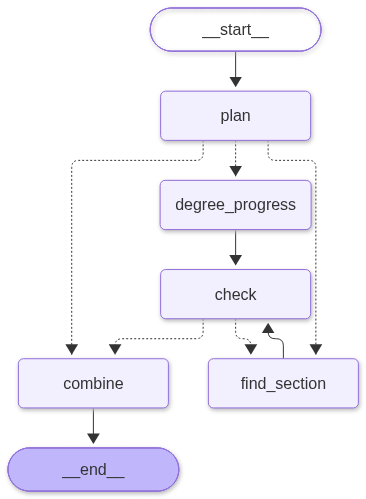

In [20]:
# DO NOT MODIFY — build and draw your graph
from IPython.display import Image, display

graph = build_graph()
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:                 # drawing uses an online service; print the graph's text without it
    print(graph.get_graph().draw_mermaid())

## 10. Run the public questions

The runner sends each public question through your graph and checks the answer against the rules in `data/README.md`:

- **Degree progress:** `missing` must be exactly the required courses the student has not passed (in any order), and `choose_one_done` must be right.
- **Section picks:** when a section fits, any section that follows the section-pick rules is right, not one particular id: open seats, the student can take the course, no conflict with the registered sections, and no conflict with the other picks. When no section fits, the answer must be null.
- **No student id:** the answer must say the student id is needed.

The **Specialists** column shows which specialists ran in which graph step. Parts that run in parallel share one step; a retry shows up in a later step. A full run is about 10 to 15 model calls per question.

In [21]:
# DO NOT MODIFY — the runner and the answer check
# You don't need to read this code: it runs questions through your graph, checks the answers, and saves your results.
PUBLIC_QUESTIONS = json.loads((DATA_DIR / "public_questions.json").read_text(encoding="utf-8"))


def pick_problems(student_id, course, section_id, registered=()):
    """Why a pick is not valid for this student and course on its own ([] if it is valid)."""
    if not is_open_section(section_id, course):
        return [f"{section_id} is not an open Spring 2027 section of {course}"]
    status = check_eligibility(student_id, course).get("status")
    if status not in ("eligible", "pending"):
        return [f"{student_id} cannot be given {course} (eligibility: {status})"]
    clashes = [r for r in registered if sections_conflict(section_id, r)]
    if clashes:
        return [f"{section_id} conflicts with the registered section {', '.join(clashes)}"]
    return []


def answer_problems(answer, fields, expected):
    """What is wrong with an answer (a HelpDeskAnswer as a dict) for a question; [] if it is right."""
    if not isinstance(answer, dict):
        return ["no answer"]
    if expected.get("needs_student_id"):
        return [] if answer.get("needs_student_id") else ["should say the student id is needed"]
    if answer.get("needs_student_id"):
        return ["said the student id is needed, but the message gives it"]
    problems = []
    want, got = expected.get("degree"), answer.get("degree")
    if want is None and got is not None:
        problems.append("gave degree progress the student did not ask for")
    if want is not None:
        if not isinstance(got, dict):
            problems.append("no degree progress")
        else:
            got_missing = sorted({norm_course(c) or str(c) for c in got.get("missing") or []})
            if got_missing != sorted(want["missing"]):
                problems.append(f"missing should be {', '.join(sorted(want['missing'])) or 'empty'}, "
                                f"got {', '.join(got_missing) or 'empty'}")
            if bool(got.get("choose_one_done")) != want["choose_one_done"]:
                problems.append(f"choose_one_done should be {want['choose_one_done']}")
    picks = {}
    for p in answer.get("sections") or []:
        if norm_course(p.get("course")):
            sid = p.get("section_id")
            picks[norm_course(p["course"])] = sid.strip().upper() if isinstance(sid, str) and sid.strip() else None
    student, registered = fields["student_id"], fields.get("registered", [])
    for course, kind in expected.get("sections", {}).items():
        if course not in picks:
            problems.append(f"no answer for {course}")
        elif kind == "none" and picks[course]:
            problems.append(f"{course}: no section fits, but the answer picked {picks[course]}")
        elif kind == "section" and not picks[course]:
            problems.append(f"{course}: a section fits, but the answer picked none")
        elif kind == "section":
            problems += [f"{course}: {p}" for p in pick_problems(student, course, picks[course], registered)]
    chosen = sorted((c, s) for c, s in picks.items() if s)
    for i, (c1, s1) in enumerate(chosen):
        for c2, s2 in chosen[i + 1:]:
            if sections_conflict(s1, s2):
                problems.append(f"the picks {s1} and {s2} conflict with each other")
    extra = sorted(set(picks) - set(expected.get("sections", {})))
    if extra:
        problems.append(f"answered courses the student did not ask about: {', '.join(extra)}")
    return problems


def ask(graph, request):
    """Run one message through the graph. Returns a record: the answer, the specialist calls, any error."""
    SPECIALIST_CALLS.clear()
    record = {"request": request, "answer": None, "calls": [], "error": None}
    try:
        state = graph.invoke({"request": request}, config={"recursion_limit": 30})
        answer = state.get("answer")
        record["answer"] = answer.model_dump() if isinstance(answer, BaseModel) else None
        if record["answer"] is None:
            record["error"] = "The graph ended without an answer (is combine connected to END?)."
    except Exception as exc:
        record["error"] = f"{type(exc).__name__}: {exc}"
    record["calls"] = list(SPECIALIST_CALLS)
    return record


def run_questions(graph, questions):
    """Run every question and check its answer."""
    records = []
    for q in questions:
        record = ask(graph, q["request"])
        record["id"] = q["id"]
        record["problems"] = [record["error"]] if record["error"] else answer_problems(record["answer"], q["fields"], q["expected"])
        records.append(record)
    return records


def describe_calls(calls):
    """'step 2: degree_progress, find_section ×2 · step 4: find_section' (from SPECIALIST_CALLS)."""
    steps = {}
    for c in calls:
        steps.setdefault(c["step"], []).append(c["specialist"])
    parts = []
    for step in sorted(steps, key=lambda s: (s is None, s)):
        names = steps[step]
        label = ", ".join(f"{n} ×{names.count(n)}" if names.count(n) > 1 else n for n in dict.fromkeys(names))
        parts.append(f"step {step}: {label}")
    return " · ".join(parts) or "none"


def show_results(records):
    passed = sum(not r["problems"] for r in records)
    for r in records:
        print(f"{'PASS' if not r['problems'] else 'FAIL'}  {r['id']:<22} specialists: {describe_calls(r['calls'])}")
        for p in r["problems"]:
            print(f"      - {p}")
    print(f"\n{passed}/{len(records)} pass")


def show_answer(record):
    """Print one record's answer and the briefs its specialists received."""
    a = record["answer"] or {}
    print(record["request"])
    if a.get("needs_student_id"):
        print("  -> needs a student id")
    if a.get("degree"):
        print(f"  degree: missing {a['degree']['missing']}, choose_one_done {a['degree']['choose_one_done']}")
    for p in a.get("sections") or []:
        print(f"  {p['course']}: {p['section_id']}  ({p['reason']})")
    for c in record["calls"]:
        print(f"  brief to {c['specialist']} (step {c['step']}): {c['brief']!r}")


def save_results(path, partners, public_records):
    """Write results.json: your names, your prompts, and the records of the public questions."""
    data = {"assignment": 4, "partners": partners,
            "prompts": {"PLAN_PROMPT": PLAN_PROMPT, "DEGREE_PROMPT": DEGREE_PROMPT, "FINDER_PROMPT": FINDER_PROMPT},
            "public_records": public_records}
    Path(path).write_text(json.dumps(data, indent=1, ensure_ascii=False, default=str), encoding="utf-8")
    print(f"Saved {path}: {len(public_records)} public records.")


print(f"{len(PUBLIC_QUESTIONS)} public questions loaded")

10 public questions loaded


In [23]:
# DO NOT MODIFY — run the public questions
public_records = run_questions(graph, PUBLIC_QUESTIONS)
show_results(public_records)

PASS  pub_degree_s101        specialists: step 2: degree_progress
PASS  pub_one_section_s103   specialists: step 2: find_section
PASS  pub_two_sections_s104  specialists: step 2: find_section ×2 · step 4: find_section
PASS  pub_two_sections_s105  specialists: step 2: find_section ×2
PASS  pub_both_s106          specialists: step 2: degree_progress, find_section
PASS  pub_both_s101          specialists: step 2: degree_progress, find_section ×2
PASS  pub_registered_s103    specialists: step 2: find_section
PASS  pub_not_eligible_s107  specialists: step 2: find_section
PASS  pub_no_section_s101    specialists: step 2: find_section ×3
PASS  pub_no_id              specialists: none

10/10 pass


When a question fails, read its answer and the briefs its specialists received, for example with `show_answer(public_records[0])` in a new cell (delete the cell before you submit). Decide which step went wrong: the plan, a route, a brief, a specialist's prompt or tools, or `check`. Change one thing and rerun. The public questions are in `data/public_questions.json`.

## 11. Save your results

Before saving, restart the kernel and run the whole notebook from top to bottom, so the outputs and `results.json` come from your final prompts and code. `results.json` holds your names, your three prompts, and the records of the public questions. Then run the submission check.

In [24]:
# YOUR WORK 6 — partner names, then save
PARTNERS = ["Dennis Shlaih", "Rubin Kataroshi"]
assert all(p.strip() and p != "TODO" for p in PARTNERS), "Add your names."

save_results("results.json", partners=PARTNERS, public_records=public_records)

Saved results.json: 10 public records.


The submission check reads the **saved** notebook file, so save the notebook first (**Cmd/Ctrl+S**). It then runs your YOUR WORK cells on their own, the way they will be run after you submit, and compares them with `results.json`. Fix anything marked ✗, then save and run it again.

In [168]:
# DO NOT MODIFY — submission check
# You don't need to read this code: it checks that your saved notebook and results.json are ready to submit.
import ast
import contextlib
import io
import types


def _notebook_path():
    vscode = globals().get("__vsc_ipynb_file__")
    if vscode and Path(vscode).exists():
        return Path(vscode)
    found = sorted((p for p in Path(".").glob("*.ipynb") if "Instructor" not in p.name), key=lambda p: p.stat().st_mtime)
    return found[-1] if found else None


def _cells_by_title(nb):
    out = {}
    for cell in nb["cells"]:
        source = "".join(cell["source"])
        first = source.strip().splitlines()[0] if source.strip() else ""
        m = re.match(r"#\s*(DO NOT MODIFY|YOUR WORK \d+)\s*[—-]+\s*(.+)", first)
        if cell["cell_type"] == "code" and m:
            out[m.group(1) if m.group(1).startswith("YOUR WORK") else m.group(2).strip()] = source
    return out


_DEFINITION_CELLS = ["imports", "load the Riverview data and helpers", "the five tools", "the answer formats",
                     "the shared state", "YOUR WORK 1", "the plan node", "YOUR WORK 2", "the specialist wrapper", "YOUR WORK 3", "helpers for check", "YOUR WORK 4",
                     "the combine node", "YOUR WORK 5", "the runner and the answer check"]


def _squash(text):
    return re.sub(r"\s+", " ", str(text)).strip()


def check_submission(results_path="results.json"):
    rows = []
    path = _notebook_path()
    if path is None:
        print("✗ No notebook file found next to the data/ folder.")
        return
    nb = json.loads(path.read_text(encoding="utf-8"))
    cells = _cells_by_title(nb)
    missing = [f"YOUR WORK {n}" for n in range(1, 7) if f"YOUR WORK {n}" not in cells]
    rows.append((not missing, "Every YOUR WORK cell is found, with its first line unchanged",
                 f"not found: {', '.join(missing)}. Restore the first line of each cell." if missing else ""))

    ns = types.ModuleType("submission_check").__dict__
    errors = []
    with contextlib.redirect_stdout(io.StringIO()):
        for title in _DEFINITION_CELLS:
            if title in cells:
                try:
                    exec(compile(cells[title], f"<{title}>", "exec"), ns)
                except Exception as exc:
                    errors.append(f"{title}: {type(exc).__name__}: {exc}")
    needed = ["PLAN_PROMPT", "route", "degree_progress", "find_section", "check", "after_check", "build_graph"]
    undefined = [n for n in needed if n not in ns]
    rows.append((not errors and not undefined, "Your cells run on their own, in order",
                 "; ".join(errors + ([f"not defined: {', '.join(undefined)}"] if undefined else []))
                 + " Keep every helper inside its YOUR WORK cell." if errors or undefined else ""))
    try:
        ns["build_graph"]()
        rows.append((True, "build_graph() builds a graph", ""))
    except Exception as exc:
        rows.append((False, "build_graph() builds a graph", f"{type(exc).__name__}: {exc}"))

    names = re.search(r"PARTNERS\s*=\s*(\[.*?\])", cells.get("YOUR WORK 6", ""), re.S)
    try:
        partners = [p for p in ast.literal_eval(names.group(1)) if isinstance(p, str) and p.strip() and p != "TODO"] if names else []
    except (ValueError, SyntaxError):
        partners = []
    rows.append((bool(partners), "Partner names are filled in", "" if partners else "add your names in YOUR WORK 6"))
    disclosure = next(("".join(c["source"]) for c in nb["cells"] if c["cell_type"] == "markdown"
                       and "YOUR WORK 7" in "".join(c["source"])), "")
    answer = disclosure.split("**Your answer:**")[-1] if "**Your answer:**" in disclosure else ""
    rows.append((bool(answer.strip()) and "TODO" not in answer, "The AI-assistance disclosure is answered",
                 "" if answer.strip() and "TODO" not in answer else "answer YOUR WORK 7 in §12"))

    results = Path(results_path)
    if not results.exists():
        rows.append((False, "results.json was saved after your last change", "run YOUR WORK 6"))
    else:
        saved = json.loads(results.read_text(encoding="utf-8"))
        same = all(_squash(saved.get("prompts", {}).get(k)) == _squash(ns.get(k)) for k in
                   ("PLAN_PROMPT", "DEGREE_PROMPT", "FINDER_PROMPT"))
        rows.append((same, "results.json was saved after your last change",
                     "" if same else "your prompts changed after saving: rerun the notebook and YOUR WORK 6"))

    print(f"Checked {path.name} (saved {len(nb['cells'])} cells)\n")
    for ok, label, fix in rows:
        print(f"{'✓' if ok else '✗'} {label}" + (f"\n    {fix}" if not ok and fix else ""))
    print("\nReady to submit." if all(ok for ok, _, _ in rows) else "\nFix the items marked ✗, save, and run this cell again.")


check_submission()

Checked Assignment04_Multiagent_Help_Desk.ipynb (saved 50 cells)

✓ Every YOUR WORK cell is found, with its first line unchanged
✓ Your cells run on their own, in order
✓ build_graph() builds a graph
✓ Partner names are filled in
✓ The AI-assistance disclosure is answered
✓ results.json was saved after your last change

Ready to submit.


## 12. Use of coding or AI assistants

**YOUR WORK 7:** Briefly state whether you used a coding or AI assistant. If you did, describe what you asked it to help you understand or debug, what suggestions you accepted or rejected, and how you verified the submitted work. If you did not use one, state that directly.

**Your answer:** Used Claude to help debug and later I verifed by running each specialist on one task outside the graph, reading the tool-call trace to see that each one called only its own tools and used the results. 

I also used it to help with the testing phase. I used the results from the system, tool calls, specialists, and tool-call traces in order to determine the cause of failure. I then asked Claude to see its suggestions and compared it with my findings. A suggestion that I accepted was to edit the rules regarding how missing is calculated, and I confirmed that this was the cause by running the degree specialist tools and comparing the output to the specialist's output on the case. However, I also rejected certain suggestions such as changing degree_progress directly to have a more deterministic solution by using python to calculate degree progress as opposed to relying on the LLM's output. This was a solution I considered, but I managed to fix the failures by writing more explicit definitions and supplying the specialists with a concrete procedure to follow.

## Submission checklist

- [X] Both partners' names are in YOUR WORK 6.
- [X] `route` and `check` pass every public test.
- [X] Every public question passes.
- [X] The notebook was run from top to bottom, with its outputs saved, and `results.json` was written.
- [ ] The submission check shows ✓ on every line.
- [X] The AI-assistance disclosure is complete.
- [X] No API key appears in either file.